# Tweedie Challenger – Direkte Modellierung der Pure Premium

## Ziel

In diesem Notebook wird ein Tweedie-Regressionsmodell als Challenger zum bestehenden Two-Stage-Ansatz aus Poisson-Frequenz- und Gamma-Severity-Modell entwickelt.

Das Tweedie-Modell schätzt die annualisierten erwarteten Schadenkosten direkt auf Policenebene. Dabei werden Policen ohne Schaden und Policen mit positiven Schadenbeträgen gemeinsam modelliert.

Die Modellierung basiert auf dem bereits festgelegten kanonischen Train/Test-Split. Die Modellspezifikation wird ausschließlich auf den Trainingsdaten ausgewählt; der Holdout-Datensatz wird erst nach Abschluss der Modellauswahl zur finalen Bewertung verwendet.


## Setup und Datenbasis

Für die Tweedie-Modellierung wird der bereits festgelegte kanonische Train/Test-Split verwendet. Dadurch bleibt die Vergleichbarkeit mit den bestehenden Frequency- und Severity-Modellen erhalten.

Der Split wird nicht neu erzeugt oder verändert. Alle Entscheidungen zur Modellspezifikation werden ausschließlich auf dem Trainingsdatensatz getroffen.


In [39]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Kanonischer Train/Test-Split

Für das Tweedie-Modell wird ausschließlich der bereits gespeicherte kanonische Split verwendet. Dadurch werden identische Policen wie bei den bisherigen Modellen für Training und Holdout-Bewertung verwendet.

Vor der Modellierung werden Dateipfad, Dimensionen und Split-Verteilung kontrolliert.


In [2]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SPLIT_PATH = PROJECT_ROOT / "data" / "processed" / "policy_train_test_split.pq"

print("Project root:", PROJECT_ROOT)
print("Split path:", SPLIT_PATH)
print("File exists:", SPLIT_PATH.exists())

Project root: C:\Users\Mesut\Desktop\kfz-insurance-risk-platform
Split path: C:\Users\Mesut\Desktop\kfz-insurance-risk-platform\data\processed\policy_train_test_split.pq
File exists: True


### Laden und erste Strukturkontrolle

Der gespeicherte Datensatz wird nun geladen und zunächst nur strukturell geprüft. Dabei werden Dimensionen, Spaltennamen und ein kleiner Ausschnitt kontrolliert, bevor weitere Modellierungsvariablen definiert werden.


In [3]:
split_df = pd.read_parquet(SPLIT_PATH)

print("Shape:", split_df.shape)
print("\nColumns:")
print(split_df.columns.tolist())

display(split_df.head())

Shape: (678013, 2)

Columns:
['IDpol', 'split']


,IDpol,split
0,1,train
1,3,train
2,5,test
3,10,train
4,11,train


### Validierung des gespeicherten Splits

Vor der Verknüpfung mit dem Modellierungsdatensatz wird geprüft, ob jede Police genau einmal im Split vorkommt und ob die gespeicherten Train- und Testgrößen den erwarteten Werten entsprechen.


In [4]:
print("Rows:", len(split_df))
print("Unique IDpol:", split_df["IDpol"].nunique())
print("Duplicate IDpol:", split_df["IDpol"].duplicated().sum())

print("\nSplit counts:")
print(split_df["split"].value_counts())

print("\nSplit values:")
print(sorted(split_df["split"].unique()))

Rows: 678013
Unique IDpol: 678013
Duplicate IDpol: 0

Split counts:
split
train    542410
test     135603
Name: count, dtype: int64

Split values:
['test', 'train']


### Verknüpfung mit dem kuratierten Policy-Datensatz

Der kanonische Split enthält ausschließlich die Policy-ID und die Zuordnung zu Train oder Test. Für die Modellierung wird diese Information nun mit dem kuratierten Policy-Datensatz verknüpft.

Die Verknüpfung erfolgt über `IDpol`. Anschließend wird kontrolliert, ob alle Policen vollständig erhalten bleiben und jede Policy genau einer Split-Gruppe zugeordnet ist.


In [5]:
CURATED_PATH = PROJECT_ROOT / "data" / "processed" / "policy_curated.pq"

print("Curated path:", CURATED_PATH)
print("File exists:", CURATED_PATH.exists())

Curated path: C:\Users\Mesut\Desktop\kfz-insurance-risk-platform\data\processed\policy_curated.pq
File exists: True


### Strukturkontrolle des kuratierten Datensatzes

Vor der Verknüpfung mit dem kanonischen Split wird der kuratierte Policy-Datensatz auf Dimensionen, Eindeutigkeit der Policy-ID und vorhandene Spalten geprüft.

Damit stellen wir sicher, dass die Modellierungsbasis vollständig und konsistent ist, bevor Train- und Testzuordnungen ergänzt werden.


In [6]:
curated_df = pd.read_parquet(CURATED_PATH)

print("Shape:", curated_df.shape)
print("Unique IDpol:", curated_df["IDpol"].nunique())
print("Duplicate IDpol:", curated_df["IDpol"].duplicated().sum())

print("\nColumns:")
print(curated_df.columns.tolist())

Shape: (678013, 25)
Unique IDpol: 678013
Duplicate IDpol: 0

Columns:
['IDpol', 'ClaimNb', 'Exposure', 'Area', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Density', 'Region', 'exposure_capped', 'high_claim_count', 'total_claim_amount', 'claim_record_count', 'claim_count_mismatch', 'missing_severity', 'observed_claim_frequency', 'observed_severity', 'observed_pure_premium', 'driver_age_group', 'vehicle_age_group', 'bonus_malus_segment', 'log_density']


### Verknüpfung mit dem kanonischen Split

Der kuratierte Policy-Datensatz wird über `IDpol` mit der gespeicherten Train/Test-Zuordnung verbunden.

Die Verknüpfung wird als eindeutige 1:1-Beziehung validiert. Dadurch wird sichergestellt, dass keine Policen verloren gehen, dupliziert werden oder ohne Split-Zuordnung bleiben.


In [7]:
model_df = curated_df.merge(
    split_df,
    on="IDpol",
    how="left",
    validate="one_to_one",
)

print("Shape:", model_df.shape)
print("Unique IDpol:", model_df["IDpol"].nunique())
print("Duplicate IDpol:", model_df["IDpol"].duplicated().sum())
print("Missing split:", model_df["split"].isna().sum())

print("\nSplit counts:")
print(model_df["split"].value_counts())

Shape: (678013, 26)
Unique IDpol: 678013
Duplicate IDpol: 0
Missing split: 0

Split counts:
split
train    542410
test     135603
Name: count, dtype: int64


### Prüfung fehlender Schadenbeträge

Vor der Definition des Tweedie-Targets werden fehlende Werte in `total_claim_amount` untersucht.

Dabei wird geprüft, ob diese Fälle mit Policen mit gemeldeten Schäden sowie mit den bereits vorhandenen Datenqualitätsindikatoren `missing_severity` und `claim_count_mismatch` zusammenhängen. Fehlende Schadenbeträge dürfen nicht automatisch als Nullschäden interpretiert werden.


In [8]:
missing_amount = model_df["total_claim_amount"].isna()

print("Missing total_claim_amount:", missing_amount.sum())
print(
    "Missing rate:",
    f"{missing_amount.mean():.4%}",
)

print("\nBy split:")
print(
    model_df.groupby("split")["total_claim_amount"]
    .agg(
        rows="size",
        missing=lambda s: s.isna().sum(),
    )
)

print("\nClaimNb among missing total_claim_amount:")
print(
    model_df.loc[missing_amount, "ClaimNb"]
    .value_counts()
    .sort_index()
)

print("\nDQ flags among missing total_claim_amount:")
print(
    model_df.loc[
        missing_amount,
        ["missing_severity", "claim_count_mismatch"]
    ]
    .value_counts(dropna=False)
)

Missing total_claim_amount: 9116
Missing rate: 1.3445%

By split:
         rows  missing
split                 
test   135603     1813
train  542410     7303

ClaimNb among missing total_claim_amount:
ClaimNb
1     8608
2      485
3       20
4        2
11       1
Name: count, dtype: int64

DQ flags among missing total_claim_amount:
missing_severity  claim_count_mismatch
True              False                   9116
Name: count, dtype: int64


### Umfang der fehlenden Schadenbeträge

Die fehlenden Schadenbeträge betreffen ausschließlich Policen mit mindestens einem gemeldeten Schaden. Sie stellen daher keine Nullschäden dar und dürfen bei der Tweedie-Modellierung nicht als Schadenbetrag von null interpretiert werden.

Im nächsten Schritt wird quantifiziert, welchen Anteil diese Policen an den Schadenpolicen, der Anzahl der Schäden und der Exposure ausmachen. Diese Größenordnung ist entscheidend für die Festlegung einer methodisch sauberen Modellierungs- und Vergleichsbasis.


In [9]:
claim_policy = model_df["ClaimNb"] > 0
missing_amount = model_df["total_claim_amount"].isna()

summary_missing = (
    model_df
    .assign(
        claim_policy=claim_policy,
        missing_amount=missing_amount,
        missing_claims=np.where(
            missing_amount,
            model_df["ClaimNb"],
            0,
        ),
    )
    .groupby("split")
    .agg(
        policies=("IDpol", "size"),
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
        claim_policies=("claim_policy", "sum"),
        missing_amount_policies=("missing_amount", "sum"),
        missing_claims=("missing_claims", "sum"),
    )
)

summary_missing["missing_share_claim_policies"] = (
    summary_missing["missing_amount_policies"]
    / summary_missing["claim_policies"]
)

summary_missing["missing_share_claims"] = (
    summary_missing["missing_claims"]
    / summary_missing["claims"]
)

display(summary_missing)

,policies,exposure,claims,claim_policies,missing_amount_policies,missing_claims,missing_share_claim_policies,missing_share_claims
split,,,,,,,,
test,135603,71583.602641,7236,6812,1813,1924,0.266148,0.265893
train,542410,286776.502822,28866,27248,7303,7733,0.268020,0.267893


### Einfluss der fehlenden Schadenbeträge auf die Modellierungsbasis

Da fehlende Schadenbeträge ausschließlich bei Policen mit gemeldeten Schäden auftreten, führt ein Ausschluss dieser Policen zu einer selektiven Modellierungsbasis.

Vor der Festlegung des Tweedie-Modellierungsuniversums wird daher untersucht, wie stark sich der Ausschluss auf Exposure, Schadenanzahl und beobachtete Schadenfrequenz auswirkt.


In [10]:
observable_df = model_df.loc[
    model_df["total_claim_amount"].notna()
].copy()

comparison = (
    model_df
    .groupby("split")
    .agg(
        full_policies=("IDpol", "size"),
        full_exposure=("Exposure", "sum"),
        full_claims=("ClaimNb", "sum"),
    )
)

observable_summary = (
    observable_df
    .groupby("split")
    .agg(
        observable_policies=("IDpol", "size"),
        observable_exposure=("Exposure", "sum"),
        observable_claims=("ClaimNb", "sum"),
    )
)

comparison = comparison.join(observable_summary)

comparison["full_frequency"] = (
    comparison["full_claims"]
    / comparison["full_exposure"]
)

comparison["observable_frequency"] = (
    comparison["observable_claims"]
    / comparison["observable_exposure"]
)

comparison["frequency_change_pct"] = (
    comparison["observable_frequency"]
    / comparison["full_frequency"]
    - 1
) * 100

display(comparison)

,full_policies,full_exposure,full_claims,observable_policies,observable_exposure,observable_claims,full_frequency,observable_frequency,frequency_change_pct
split,,,,,,,,,
test,135603,71583.602641,7236,133790,70664.505209,5312,0.101085,0.075172,-25.634460
train,542410,286776.502822,28866,535107,283090.142822,21133,0.100657,0.074651,-25.835963


### Festlegung des Tweedie-Modellierungsuniversums

Für 9.116 Policen mit gemeldeten Schäden ist kein vollständiger Schadenbetrag verfügbar. Diese Fälle können nicht als Nullschäden interpretiert werden und besitzen daher keinen direkt beobachtbaren Tweedie-Targetwert.

Für das überwachte Tweedie-Training werden deshalb nur Policen mit beobachtetem `total_claim_amount` verwendet. Diese Auswahl ist jedoch nicht zufällig: Obwohl nur ein kleiner Anteil aller Policen ausgeschlossen wird, entfallen dadurch rund 27 % der gemeldeten Schäden. Die beobachtete Schadenfrequenz der verbleibenden Stichprobe liegt deshalb deutlich unter der Frequenz des vollständigen Portfolios.

Das Tweedie-Modell wird daher als **selection-affected observable-loss challenger** bewertet. Kennzahlen auf dieser Teilpopulation dürfen nicht als unverzerrte Full-Portfolio-Kalibrierung interpretiert werden.

Für den späteren Vergleich mit dem Two-Stage-Modell werden beide Ansätze auf derselben beobachtbaren Holdout-Basis verglichen. Eine Full-Portfolio-Bewertung mit imputierten Schadenbeträgen wird – falls verwendet – ausschließlich als separate Sensitivitätsanalyse ausgewiesen.


In [11]:
tweedie_df = model_df.loc[
    model_df["total_claim_amount"].notna()
].copy()

print("Rows:", len(tweedie_df))

print("\nExposure checks:")
print("Missing Exposure:", tweedie_df["Exposure"].isna().sum())
print("Exposure <= 0:", (tweedie_df["Exposure"] <= 0).sum())
print("Min Exposure:", tweedie_df["Exposure"].min())
print("Max Exposure:", tweedie_df["Exposure"].max())

print("\nClaim amount checks:")
print(
    "Missing total_claim_amount:",
    tweedie_df["total_claim_amount"].isna().sum()
)
print(
    "Negative total_claim_amount:",
    (tweedie_df["total_claim_amount"] < 0).sum()
)
print(
    "Zero total_claim_amount:",
    (tweedie_df["total_claim_amount"] == 0).sum()
)
print(
    "Positive total_claim_amount:",
    (tweedie_df["total_claim_amount"] > 0).sum()
)

Rows: 668897

Exposure checks:
Missing Exposure: 0
Exposure <= 0: 0
Min Exposure: 0.00273224043715847
Max Exposure: 1.0

Claim amount checks:
Missing total_claim_amount: 0
Negative total_claim_amount: 0
Zero total_claim_amount: 643953
Positive total_claim_amount: 24944


### Konsistenzprüfung der beobachteten positiven Schäden

Vor der endgültigen Definition des Tweedie-Targets wird geprüft, ob die Policen mit beobachtetem positivem Schadenbetrag weitere Datenqualitätsauffälligkeiten aufweisen.

Insbesondere wird untersucht, ob `claim_count_mismatch` bei diesen Policen vorkommt. Da das Tweedie-Target direkt auf dem aggregierten Schadenbetrag und nicht auf der Schadenanzahl basiert, wird ein solcher Fall nicht automatisch ausgeschlossen, sondern zunächst separat bewertet.


In [12]:
positive_loss = tweedie_df["total_claim_amount"] > 0

print("Positive-loss policies:", positive_loss.sum())

print("\nDQ flags among positive-loss policies:")
print(
    tweedie_df.loc[
        positive_loss,
        ["missing_severity", "claim_count_mismatch"]
    ]
    .value_counts(dropna=False)
)

print("\nClaim-count mismatch rows:")
display(
    tweedie_df.loc[
        tweedie_df["claim_count_mismatch"],
        [
            "IDpol",
            "ClaimNb",
            "claim_record_count",
            "total_claim_amount",
            "Exposure",
            "missing_severity",
            "claim_count_mismatch",
        ]
    ]
)

Positive-loss policies: 24944

DQ flags among positive-loss policies:
missing_severity  claim_count_mismatch
False             False                   24943
                  True                        1
Name: count, dtype: int64

Claim-count mismatch rows:


,IDpol,ClaimNb,claim_record_count,total_claim_amount,Exposure,missing_severity,claim_count_mismatch
567077,4158255.0,2,1.0,543.33,0.82,False,True


### Ausschluss eines unvollständigen positiven Schadenfalls

Unter den Policen mit beobachtetem positivem Schadenbetrag wurde ein Fall mit `claim_count_mismatch = True` identifiziert. Für diese Police stehen zwei gemeldeten Schäden nur ein Schadenrecord gegenüber.

Der aggregierte beobachtete Schadenbetrag kann daher nicht als vollständig angesehen werden. Da das Tweedie-Target den gesamten Schadenbetrag der Police abbilden soll, wird diese einzelne Police aus der überwachten Tweedie-Modellierungsbasis ausgeschlossen.


In [13]:
tweedie_mask = (
    model_df["total_claim_amount"].notna()
    & ~model_df["claim_count_mismatch"]
    & (model_df["Exposure"] > 0)
    & (model_df["total_claim_amount"] >= 0)
)

tweedie_df = model_df.loc[tweedie_mask].copy()

tweedie_df["tweedie_target"] = (
    tweedie_df["total_claim_amount"]
    / tweedie_df["Exposure"]
)

print("Tweedie modelling rows:", len(tweedie_df))

print("\nSplit counts:")
print(tweedie_df["split"].value_counts())

print("\nTarget checks:")
print("Missing target:", tweedie_df["tweedie_target"].isna().sum())
print("Negative target:", (tweedie_df["tweedie_target"] < 0).sum())
print("Zero target:", (tweedie_df["tweedie_target"] == 0).sum())
print("Positive target:", (tweedie_df["tweedie_target"] > 0).sum())

print("\nTarget summary:")
print(tweedie_df["tweedie_target"].describe())

Tweedie modelling rows: 668896

Split counts:
split
train    535106
test     133790
Name: count, dtype: int64

Target checks:
Missing target: 0
Negative target: 0
Zero target: 643953
Positive target: 24943

Target summary:
count    6.688960e+05
mean     3.884931e+02
std      3.707076e+04
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.852455e+07
Name: tweedie_target, dtype: float64


### Targetstruktur und portfoliogewichtete Schadenkosten

Der Tweedie-Target ist stark null-inflationiert und weist bei positiven Schäden eine ausgeprägte Rechtsschiefe auf. Aufgrund der Annualisierung können insbesondere Policen mit kurzer Exposure sehr hohe Targetwerte aufweisen.

Für die Portfoliointerpretation ist deshalb nicht der einfache arithmetische Mittelwert des Targets maßgeblich. Entscheidend ist der exposure-gewichtete Mittelwert, der dem gesamten beobachteten Schadenbetrag dividiert durch die gesamte Exposure entspricht.


In [14]:
tweedie_summary = (
    tweedie_df
    .assign(
        positive_loss=tweedie_df["total_claim_amount"] > 0
    )
    .groupby("split")
    .agg(
        policies=("IDpol", "size"),
        exposure=("Exposure", "sum"),
        total_loss=("total_claim_amount", "sum"),
        positive_loss_policies=("positive_loss", "sum"),
        mean_target=("tweedie_target", "mean"),
    )
)

tweedie_summary["positive_loss_share"] = (
    tweedie_summary["positive_loss_policies"]
    / tweedie_summary["policies"]
)

tweedie_summary["exposure_weighted_pure_premium"] = (
    tweedie_summary["total_loss"]
    / tweedie_summary["exposure"]
)

display(tweedie_summary)

,policies,exposure,total_loss,positive_loss_policies,mean_target,positive_loss_share,exposure_weighted_pure_premium
split,,,,,,,
test,133790,70664.505209,11055690.67,4999,294.632665,0.037365,156.453238
train,535106,283089.322822,48852982.50,19944,411.960568,0.037271,172.570912


In [40]:
positive_target = tweedie_df.loc[
    tweedie_df["tweedie_target"] > 0,
    "tweedie_target",
]

### Verteilung der positiven Tweedie-Targets

Da der überwiegende Teil der Policen keinen beobachteten Schaden aufweist, wird die Verteilung der positiven Tweedie-Targets separat betrachtet.

Zur besseren Darstellung der stark rechtsschiefen Verteilung wird eine logarithmische x-Achse verwendet. Die Darstellung dient ausschließlich der Diagnose der Targetstruktur; aus ihr wird keine automatische Capping- oder Winsorizing-Regel abgeleitet.


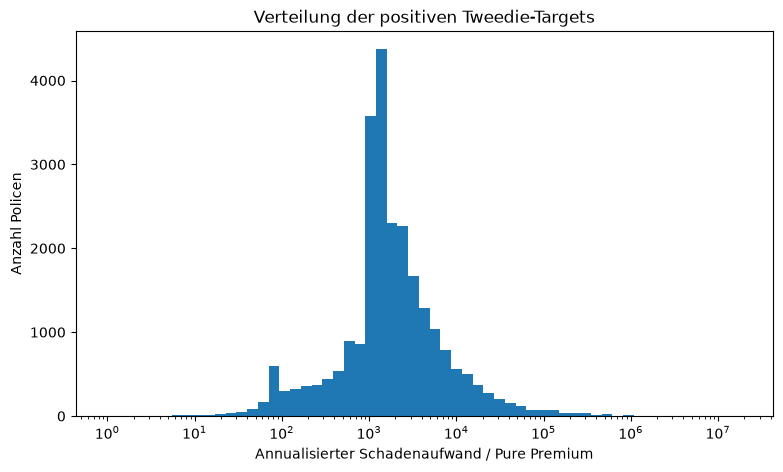

In [16]:
log_bins = np.logspace(
    np.log10(positive_target.min()),
    np.log10(positive_target.max()),
    60
)

plt.figure(figsize=(9, 5))

plt.hist(
    positive_target,
    bins=log_bins
)

plt.xscale("log")
plt.xlabel("Annualisierter Schadenaufwand / Pure Premium")
plt.ylabel("Anzahl Policen")
plt.title("Verteilung der positiven Tweedie-Targets")
plt.show()

**Ergebnis.** Die positiven Tweedie-Targets konzentrieren sich überwiegend im Bereich um etwa \(10^3\) Euro, weisen jedoch eine deutlich rechtsschiefe Verteilung mit einem langen oberen Rand auf. Einzelne annualisierte Schadenwerte reichen bis in sehr hohe Größenordnungen. Diese Struktur ist für Versicherungsschäden plausibel und bestätigt die Notwendigkeit einer Modellierung, die sowohl Nullschäden als auch stark streuende positive Schadenbeträge berücksichtigt. Eine Kappung oder Winsorisierung wird daraus nicht automatisch abgeleitet.



## Vorbereitung der Modellierungsdaten

Für die Tweedie-Modellierung werden Trainings- und Holdout-Daten anhand des bereits festgelegten kanonischen Splits getrennt.

Der Targetwert entspricht den annualisierten Schadenkosten:

$$
y_i = \frac{\text{total\_claim\_amount}_i}{\text{Exposure}_i}
$$

Die Exposure wird als Beobachtungsgewicht verwendet. Dadurch erhalten Policen mit längerer beobachteter Risikodauer ein entsprechend höheres Gewicht bei der Modellschätzung und -bewertung.


In [17]:
train_df = tweedie_df.loc[
    tweedie_df["split"] == "train"
].copy()

test_df = tweedie_df.loc[
    tweedie_df["split"] == "test"
].copy()

y_train = train_df["tweedie_target"]
y_test = test_df["tweedie_target"]

w_train = train_df["Exposure"]
w_test = test_df["Exposure"]

print("Train rows:", len(train_df))
print("Test rows:", len(test_df))

print("\nTrain Exposure:", w_train.sum())
print("Test Exposure:", w_test.sum())

print("\nTrain weighted Pure Premium:")
print(np.average(y_train, weights=w_train))

print("\nTest weighted Pure Premium:")
print(np.average(y_test, weights=w_test))

Train rows: 535106
Test rows: 133790

Train Exposure: 283089.32282206754
Test Exposure: 70664.50520922225

Train weighted Pure Premium:
172.5709115871741

Test weighted Pure Premium:
156.453238259668


### Konstantes Tweedie-Baseline-Modell

Als erste Referenz wird ein konstantes Baseline-Modell verwendet. Dieses Modell berücksichtigt keine Risikomerkmale und prognostiziert für jede Police denselben erwarteten Schadenaufwand.

Die konstante Vorhersage entspricht dem exposure-gewichteten Mittelwert des Tweedie-Targets im Trainingsdatensatz. Damit dient die Baseline als einfache Referenz dafür, ob ein späteres Risikomodell durch die verwendeten Merkmale tatsächlich zusätzliche Information gewinnt.


In [19]:
from sklearn.metrics import mean_tweedie_deviance

TWEEDIE_POWER = 1.9

baseline_value = np.average(
    y_train,
    weights=w_train
)

baseline_pred_train = np.full(
    len(y_train),
    baseline_value
)

baseline_deviance_train = mean_tweedie_deviance(
    y_train,
    baseline_pred_train,
    sample_weight=w_train,
    power=TWEEDIE_POWER,
)

print("Tweedie power:", TWEEDIE_POWER)
print("Constant baseline:", baseline_value)
print("Train Mean Tweedie Deviance:", baseline_deviance_train)

Tweedie power: 1.9
Constant baseline: 172.5709115871741
Train Mean Tweedie Deviance: 34.98133525559286


**Ergebnis.** Das konstante Baseline-Modell prognostiziert für jede Police einen annualisierten Schadenaufwand von 172,57 Euro. Bei einem Tweedie-Powerparameter von 1,9 ergibt sich auf den Trainingsdaten eine Mean Tweedie Deviance von 34,9813. Dieser Wert dient als Referenz für die nachfolgenden risikodifferenzierenden Modelle.


### Auswahl der Modellmerkmale

Für den ersten risikodifferenzierenden Tweedie-Challenger wird die Merkmalsstruktur des finalen Frequency-Modells als Ausgangspunkt verwendet. Dadurch bleibt die Informationsbasis weitgehend mit dem bestehenden Two-Stage-Ansatz vergleichbar.

Schadenbezogene Ziel- und Diagnosevariablen werden nicht als Prädiktoren verwendet, um Target Leakage zu vermeiden.


In [20]:
categorical_features = [
    "VehPower",
    "VehBrand",
    "VehGas",
    "Region",
    "driver_age_group",
    "vehicle_age_group",
    "bonus_malus_segment",
]

spline_features = [
    "DrivAge",
    "VehAge",
    "BonusMalus",
]

linear_features = [
    "log_density",
]

feature_columns = (
    categorical_features
    + spline_features
    + linear_features
)

print("Number of model features:", len(feature_columns))
print("\nFeatures:")
print(feature_columns)

print("\nMissing values in train:")
print(train_df[feature_columns].isna().sum())

print("\nMissing values in test:")
print(test_df[feature_columns].isna().sum())

Number of model features: 11

Features:
['VehPower', 'VehBrand', 'VehGas', 'Region', 'driver_age_group', 'vehicle_age_group', 'bonus_malus_segment', 'DrivAge', 'VehAge', 'BonusMalus', 'log_density']

Missing values in train:
VehPower               0
VehBrand               0
VehGas                 0
Region                 0
driver_age_group       0
vehicle_age_group      0
bonus_malus_segment    0
DrivAge                0
VehAge                 0
BonusMalus             0
log_density            0
dtype: int64

Missing values in test:
VehPower               0
VehBrand               0
VehGas                 0
Region                 0
driver_age_group       0
vehicle_age_group      0
bonus_malus_segment    0
DrivAge                0
VehAge                 0
BonusMalus             0
log_density            0
dtype: int64


### Ausgangsspezifikation des Tweedie-Challengers

Für den ersten Tweedie-Challenger wird die tatsächlich im finalen Frequency-v2-Modell verwendete Preprocessing-Struktur übernommen. Dadurch wird die Informationsbasis zwischen dem direkten Tweedie-Ansatz und dem bestehenden Frequency-Modell möglichst vergleichbar gehalten.

Verwendet werden vier kategoriale Merkmale, drei numerische Merkmale mit Quantil-Splines sowie `log_density` als linearer numerischer Prädiktor. Die zuvor erzeugten gruppierten Alters- und Bonus-Malus-Merkmale sind im finalen Frequency-v2-Preprocessor nicht enthalten und werden deshalb auch in dieser Ausgangsspezifikation nicht verwendet.


In [21]:
tweedie_categorical_features = [
    "VehPower",
    "VehBrand",
    "VehGas",
    "Region",
]

tweedie_spline_features = [
    "DrivAge",
    "VehAge",
    "BonusMalus",
]

tweedie_linear_features = [
    "log_density",
]

tweedie_features = (
    tweedie_categorical_features
    + tweedie_spline_features
    + tweedie_linear_features
)

X_train = train_df[tweedie_features].copy()
X_test = test_df[tweedie_features].copy()

print("Tweedie raw features:", len(tweedie_features))
print(tweedie_features)
print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

Tweedie raw features: 8
['VehPower', 'VehBrand', 'VehGas', 'Region', 'DrivAge', 'VehAge', 'BonusMalus', 'log_density']

X_train shape: (535106, 8)
X_test shape: (133790, 8)


## Train-seitige Cross-Validation

Die Modellspezifikation des Tweedie-Challengers wird ausschließlich auf den Trainingsdaten ausgewählt. Der Holdout-Datensatz bleibt bis zum Abschluss der Modellauswahl unberührt.

Aufgrund des hohen Anteils an Nullschäden und der stark rechtsschiefen Verteilung der positiven Schadenwerte wird eine stratifizierte 5-Fold-Cross-Validation verwendet. Nullschäden bilden eine eigene Stratum-Gruppe; positive Tweedie-Targets werden zusätzlich nach ihrer Größenordnung in Quantilgruppen unterteilt.

Dadurch sollen sowohl die Nullschadenquote als auch die Verteilung der positiven Schadenwerte möglichst ausgewogen auf die Validierungsfolds verteilt werden.


In [22]:
from sklearn.model_selection import StratifiedKFold

positive_train = y_train > 0

cv_stratify = pd.Series(
    "zero",
    index=y_train.index,
    dtype="object",
)

positive_quantile_bins = pd.qcut(
    y_train.loc[positive_train],
    q=5,
    labels=False,
    duplicates="drop",
)

cv_stratify.loc[positive_train] = (
    "positive_q"
    + (positive_quantile_bins + 1)
    .astype(str)
)

print("CV stratification groups:")
print(cv_stratify.value_counts().sort_index())

print("\nShares:")
print(
    cv_stratify
    .value_counts(normalize=True)
    .sort_index()
    .map(lambda x: f"{x:.4%}")
)

CV stratification groups:
positive_q1      3989
positive_q2      4159
positive_q3      3818
positive_q4      4011
positive_q5      3967
zero           515162
Name: count, dtype: int64

Shares:
positive_q1     0.7455%
positive_q2     0.7772%
positive_q3     0.7135%
positive_q4     0.7496%
positive_q5     0.7413%
zero           96.2729%
Name: proportion, dtype: object


### Kontrolle der Fold-Struktur

Vor dem eigentlichen Modellvergleich wird überprüft, ob die stratifizierten Cross-Validation-Folds nicht nur hinsichtlich der Null- und Positivschaden-Gruppen, sondern auch hinsichtlich Exposure und beobachtetem Gesamtschaden hinreichend ausgewogen sind.

Aufgrund der starken Rechtsschiefe können einzelne Großschäden die Schadenkosten eines Folds deutlich beeinflussen. Deshalb werden die exposure-gewichteten Schadenkosten je Validierungsfold zusätzlich kontrolliert.


In [23]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

cv_splits = list(
    cv.split(
        X_train,
        cv_stratify,
    )
)

fold_diagnostics = []

for fold, (_, val_idx) in enumerate(
    cv_splits,
    start=1,
):
    fold_df = train_df.iloc[val_idx]

    fold_exposure = fold_df["Exposure"].sum()
    fold_loss = fold_df["total_claim_amount"].sum()

    fold_diagnostics.append({
        "fold": fold,
        "rows": len(fold_df),
        "exposure": fold_exposure,
        "positive_loss_policies": (
            fold_df["total_claim_amount"] > 0
        ).sum(),
        "positive_loss_share": (
            fold_df["total_claim_amount"] > 0
        ).mean(),
        "total_loss": fold_loss,
        "weighted_pure_premium": (
            fold_loss / fold_exposure
        ),
    })

fold_diagnostics_df = pd.DataFrame(
    fold_diagnostics
)

display(fold_diagnostics_df)

,fold,rows,exposure,positive_loss_policies,positive_loss_share,total_loss,weighted_pure_premium
0,1,107022,56440.850280,3989,0.037273,11159169.65,197.714414
1,2,107021,56618.748054,3989,0.037273,12746352.76,225.126009
2,3,107021,56868.620448,3989,0.037273,8868669.29,155.950139
3,4,107021,56687.712791,3989,0.037273,8236011.37,145.287417
4,5,107021,56473.391250,3988,0.037264,7842779.43,138.875659


**Ergebnis.** Die stratifizierte Aufteilung gleicht die Anzahl der Policen und den Anteil positiver Schadenfälle sehr gut aus. Die exposure-gewichteten Schadenkosten unterscheiden sich zwischen den Validierungsfolds jedoch weiterhin deutlich. Ursache ist der starke Einfluss einzelner Großschäden. Für eine stabilere Tweedie-Modellauswahl wird deshalb eine heavy-tail-aware Fold-Konstruktion verwendet.


### Finales Validierungsprotokoll für die Modellauswahl

Die Auswahl der Tweedie-Modellspezifikation erfolgt mit fünf unterschiedlichen Zufalls-Seeds und jeweils fünf stratifizierten Folds.

Für jeden Seed werden vollständige Out-of-Fold-Vorhersagen erzeugt. Die Bewertung erfolgt anschließend als exposure-gewichtete Mean Tweedie Deviance über alle Trainingsbeobachtungen. Zusätzlich wird die Streuung der gepoolten Deviance zwischen den Seeds dokumentiert.

Auch das konstante Baseline-Modell wird innerhalb derselben Cross-Validation-Struktur geschätzt, damit der Vergleich ohne Informationsvorteil durch die Validierungsdaten erfolgt.


In [28]:
cv_seeds = [
    42,
    52,
    62,
    72,
    82,
]

cv_baseline_results = []

for seed in cv_seeds:

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    oof_baseline_pred = np.empty(
        len(y_train),
        dtype=float,
    )

    for fit_idx, val_idx in cv.split(
        X_train,
        cv_stratify,
    ):

        y_fit = y_train.iloc[fit_idx]
        w_fit = w_train.iloc[fit_idx]

        fold_baseline = np.average(
            y_fit,
            weights=w_fit,
        )

        oof_baseline_pred[val_idx] = (
            fold_baseline
        )

    pooled_deviance = mean_tweedie_deviance(
        y_train,
        oof_baseline_pred,
        sample_weight=w_train,
        power=TWEEDIE_POWER,
    )

    cv_baseline_results.append({
        "seed": seed,
        "pooled_deviance": pooled_deviance,
    })

cv_baseline_results_df = pd.DataFrame(
    cv_baseline_results
)

display(cv_baseline_results_df)

print(
    "\nMean pooled baseline deviance:",
    cv_baseline_results_df[
        "pooled_deviance"
    ].mean(),
)

print(
    "Std pooled baseline deviance:",
    cv_baseline_results_df[
        "pooled_deviance"
    ].std(),
)

,seed,pooled_deviance
0,42,35.017407
1,52,35.002301
2,62,35.008893
3,72,34.996315
4,82,35.017626



Mean pooled baseline deviance: 35.008508307368686
Std pooled baseline deviance: 0.00934975405811761


**Ergebnis.** Das konstante Baseline-Modell erreicht über fünf unterschiedliche Cross-Validation-Seeds eine mittlere gepoolte Tweedie-Deviance von 35,0085 bei einer sehr geringen Standardabweichung von 0,0093. Die Baseline ist damit gegenüber unterschiedlichen Fold-Zuordnungen sehr stabil und bildet einen belastbaren Referenzwert für den Tweedie-Challenger.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import TweedieRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer


def make_tweedie_pipeline(
    power=1.9,
    alpha=0.0,
    max_iter=1500,
):
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    drop="first",
                ),
                tweedie_categorical_features,
            ),
            (
                "spline",
                SplineTransformer(
                    n_knots=8,
                    degree=2,
                    knots="quantile",
                    include_bias=False,
                ),
                tweedie_spline_features,
            ),
            (
                "numeric",
                "passthrough",
                tweedie_linear_features,
            ),
        ],
        remainder="drop",
    )

    return Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor,
            ),
            (
                "model",
                TweedieRegressor(
                    power=power,
                    alpha=alpha,
                    link="log",
                    max_iter=max_iter,
                ),
            ),
        ]
    )

In [31]:
initial_tweedie_pipeline = make_tweedie_pipeline(
    power=1.9,
    alpha=0.0,
)

print(initial_tweedie_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['VehPower', 'VehBrand',
                                                   'VehGas', 'Region']),
                                                 ('spline',
                                                  SplineTransformer(degree=2,
                                                                    include_bias=False,
                                                                    knots='quantile',
                                                                    n_knots=8),
                                                  ['DrivAge', 'VehAge',
                                                   'BonusMalus']),
                                                 ('nume

### Erste Tweedie-Challenger-Spezifikation

Die erste risikodifferenzierende Tweedie-Spezifikation verwendet einen Powerparameter von 1,9 und zunächst keine Regularisierung (`alpha = 0`).

Die Bewertung erfolgt ausschließlich mit wiederholter 5-Fold-Cross-Validation auf den Trainingsdaten. Für jeden Seed werden vollständige Out-of-Fold-Vorhersagen erzeugt und anschließend exposure-gewichtet mit der Mean Tweedie Deviance bewertet.

Zusätzlich wird die aggregierte Schadenkalibrierung innerhalb der Out-of-Fold-Vorhersagen kontrolliert.


In [ ]:
initial_tweedie_cv_results = []

actual_train_loss = np.sum(
    y_train.to_numpy()
    * w_train.to_numpy()
)

for seed in cv_seeds:

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    oof_pred = np.empty(
        len(y_train),
        dtype=float,
    )

    fold_iterations = []

    for fit_idx, val_idx in cv.split(
        X_train,
        cv_stratify,
    ):

        X_fit = X_train.iloc[fit_idx]
        X_val = X_train.iloc[val_idx]

        y_fit = y_train.iloc[fit_idx]
        w_fit = w_train.iloc[fit_idx]

        pipeline = make_tweedie_pipeline(
            power=1.9,
            alpha=0.0,
        )

        pipeline.fit(
            X_fit,
            y_fit,
            model__sample_weight=w_fit,
        )

        oof_pred[val_idx] = pipeline.predict(
            X_val
        )

        fold_iterations.append(
            pipeline
            .named_steps["model"]
            .n_iter_
        )

    pooled_deviance = mean_tweedie_deviance(
        y_train,
        oof_pred,
        sample_weight=w_train,
        power=1.9,
    )

    predicted_train_loss = np.sum(
        oof_pred
        * w_train.to_numpy()
    )

    loss_deviation_pct = (
        predicted_train_loss
        / actual_train_loss
        - 1
    )

    initial_tweedie_cv_results.append({
        "seed": seed,
        "pooled_deviance": pooled_deviance,
        "predicted_loss": predicted_train_loss,
        "loss_deviation_pct": loss_deviation_pct,
        "mean_iterations": np.mean(
            fold_iterations
        ),
        "max_iterations": np.max(
            fold_iterations
        ),
    })

initial_tweedie_cv_results_df = pd.DataFrame(
    initial_tweedie_cv_results
)

display(
    initial_tweedie_cv_results_df
)

print(
    "\nMean pooled Tweedie deviance:",
    initial_tweedie_cv_results_df[
        "pooled_deviance"
    ].mean(),
)

print(
    "Std pooled Tweedie deviance:",
    initial_tweedie_cv_results_df[
        "pooled_deviance"
    ].std(),
)

print(
    "\nCV baseline mean deviance:",
    cv_baseline_results_df[
        "pooled_deviance"
    ].mean(),
)

,seed,pooled_deviance,predicted_loss,loss_deviation_pct,mean_iterations,max_iterations
0,42,34.070156,4.720681e+07,-0.033696,421.8,446
1,52,34.048688,4.718759e+07,-0.034090,426.0,456
2,62,34.061995,4.713616e+07,-0.035143,375.2,422
3,72,34.056601,4.718788e+07,-0.034084,380.0,434
4,82,34.065743,4.726000e+07,-0.032608,439.6,519



Mean pooled Tweedie deviance: 34.06063664147075
Std pooled Tweedie deviance: 0.00833090811137092

CV baseline mean deviance: 35.008508307368686


**Ergebnis.** Die erste Tweedie-Spezifikation mit `power = 1,9` und `alpha = 0` verbessert die mittlere gepoolte Cross-Validation-Deviance von 35,0085 auf 34,0606. Dies entspricht einer Verbesserung von rund 2,71 % gegenüber der konstanten Baseline. Die Ergebnisse sind über die fünf Seeds sehr stabil. Die Out-of-Fold-Prognosen unterschätzen das beobachtete Gesamtschadenvolumen jedoch im Mittel um rund 3,4 %. Hinweise auf Konvergenzprobleme bestehen nicht.


In [41]:
import warnings
from sklearn.exceptions import ConvergenceWarning

screen_powers = [1.5, 1.7, 1.9]

SCREEN_SEED = 42
SCREEN_MAX_ITER = 800

power_screen_results = []

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SCREEN_SEED,
)

screen_splits = list(
    cv.split(
        X_train,
        cv_stratify,
    )
)

for candidate_power in screen_powers:

    oof_pred = np.empty(
        len(y_train),
        dtype=float,
    )

    fold_iterations = []
    converged = True
    failed_fold = None

    for fold, (fit_idx, val_idx) in enumerate(
        screen_splits,
        start=1,
    ):

        pipeline = make_tweedie_pipeline(
            power=candidate_power,
            alpha=0.0,
            max_iter=SCREEN_MAX_ITER,
        )

        try:
            with warnings.catch_warnings():
                warnings.simplefilter(
                    "error",
                    ConvergenceWarning,
                )

                pipeline.fit(
                    X_train.iloc[fit_idx],
                    y_train.iloc[fit_idx],
                    model__sample_weight=w_train.iloc[fit_idx],
                )

        except ConvergenceWarning:
            converged = False
            failed_fold = fold
            break

        oof_pred[val_idx] = pipeline.predict(
            X_train.iloc[val_idx]
        )

        fold_iterations.append(
            pipeline.named_steps["model"].n_iter_
        )

    if converged:

        pooled_deviance = mean_tweedie_deviance(
            y_train,
            oof_pred,
            sample_weight=w_train,
            power=1.9,
        )

        max_iterations = np.max(
            fold_iterations
        )

    else:

        pooled_deviance = np.nan
        max_iterations = SCREEN_MAX_ITER

    power_screen_results.append({
        "power": candidate_power,
        "converged": converged,
        "failed_fold": failed_fold,
        "pooled_deviance": pooled_deviance,
        "max_iterations": max_iterations,
    })

power_screen_results_df = pd.DataFrame(
    power_screen_results
)

display(power_screen_results_df)

,power,converged,failed_fold,pooled_deviance,max_iterations
0,1.5,False,1.0,NaN,800
1,1.7,False,2.0,NaN,800
2,1.9,True,NaN,34.070156,446


### Auswahl des Tweedie-Powerparameters

Das numerische Screening bestätigt `power = 1,9` als stabile Spezifikation für die weitere Modellierung.

Die Kandidaten `power = 1,5` und `power = 1,7` erreichten innerhalb des festgelegten Limits von 800 Iterationen nicht in allen Folds eine Konvergenz. `power = 1,9` konvergierte dagegen in allen fünf Folds und benötigte maximal 446 Iterationen. Die gepoolte Deviance für den Screening-Seed beträgt 34,0702.

Daher wird `power = 1,9` für die weitere Tweedie-Modellierung festgelegt. Weitere Power-Suchen werden nicht durchgeführt.

In [42]:
alpha_candidates = [
    0.0,
    0.01,
    0.1,
]

ALPHA_SCREEN_SEED = 42

alpha_screen_results = []

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=ALPHA_SCREEN_SEED,
)

alpha_screen_splits = list(
    cv.split(
        X_train,
        cv_stratify,
    )
)

for candidate_alpha in alpha_candidates:

    oof_pred = np.empty(
        len(y_train),
        dtype=float,
    )

    fold_iterations = []

    for fit_idx, val_idx in alpha_screen_splits:

        pipeline = make_tweedie_pipeline(
            power=1.9,
            alpha=candidate_alpha,
            max_iter=1500,
        )

        pipeline.fit(
            X_train.iloc[fit_idx],
            y_train.iloc[fit_idx],
            model__sample_weight=w_train.iloc[fit_idx],
        )

        oof_pred[val_idx] = pipeline.predict(
            X_train.iloc[val_idx]
        )

        fold_iterations.append(
            pipeline.named_steps["model"].n_iter_
        )

    pooled_deviance = mean_tweedie_deviance(
        y_train,
        oof_pred,
        sample_weight=w_train,
        power=1.9,
    )

    predicted_loss = np.sum(
        oof_pred * w_train.to_numpy()
    )

    loss_deviation_pct = (
        predicted_loss
        / actual_train_loss
        - 1
    )

    alpha_screen_results.append({
        "alpha": candidate_alpha,
        "pooled_deviance": pooled_deviance,
        "loss_deviation_pct": loss_deviation_pct,
        "mean_iterations": np.mean(
            fold_iterations
        ),
        "max_iterations": np.max(
            fold_iterations
        ),
    })

alpha_screen_results_df = pd.DataFrame(
    alpha_screen_results
)

display(alpha_screen_results_df)

,alpha,pooled_deviance,loss_deviation_pct,mean_iterations,max_iterations
0,0.00,34.070156,-0.033696,421.8,446
1,0.01,34.177622,-0.106269,86.6,113
2,0.10,34.324374,-0.112943,51.2,57


### Auswahl des Regularisierungsparameters

Für den Regularisierungsparameter wurden `alpha = 0`, `0,01` und `0,10` auf den Trainingsdaten verglichen.

Die unregularisierte Spezifikation mit `alpha = 0` erzielt mit 34,0702 die niedrigste gepoolte Tweedie-Deviance. Gleichzeitig beträgt die Abweichung des vorhergesagten Gesamtschadenvolumens lediglich rund −3,37 %.

Die stärkeren Regularisierungen konvergieren zwar deutlich schneller, verschlechtern jedoch sowohl die Deviance als auch die Portfolio-Kalibrierung. Bei `alpha = 0,01` beziehungsweise `0,10` wird das Gesamtschadenvolumen um rund 10,63 % beziehungsweise 11,29 % unterschätzt.

Daher wird `alpha = 0` für das finale Tweedie-Modell festgelegt.


### Finale Holdout-Evaluierung

Nach Abschluss der Modellspezifikation auf den Trainingsdaten wird das finale Tweedie-Modell mit `power = 1,9` und `alpha = 0` auf dem vollständigen Trainingsdatensatz geschätzt.

Der Holdout-Datensatz wird erst nach Abschluss der Modellauswahl verwendet. Bewertet werden die Mean Tweedie Deviance, die Verbesserung gegenüber einer konstanten Trainings-Baseline sowie die Kalibrierung des vorhergesagten Gesamtschadenvolumens.

Die Bewertung bezieht sich auf das zuvor definierte beobachtbare Schadenuniversum und ist daher als selection-affected Holdout-Evaluierung zu interpretieren.

In [43]:
final_tweedie_pipeline = make_tweedie_pipeline(
    power=1.9,
    alpha=0.0,
    max_iter=1500,
)

final_tweedie_pipeline.fit(
    X_train,
    y_train,
    model__sample_weight=w_train,
)

tweedie_pred_test = final_tweedie_pipeline.predict(
    X_test
)

baseline_pred_test = np.full(
    len(y_test),
    baseline_value,
)

baseline_deviance_test = mean_tweedie_deviance(
    y_test,
    baseline_pred_test,
    sample_weight=w_test,
    power=1.9,
)

tweedie_deviance_test = mean_tweedie_deviance(
    y_test,
    tweedie_pred_test,
    sample_weight=w_test,
    power=1.9,
)

tweedie_d2 = (
    1
    - tweedie_deviance_test
    / baseline_deviance_test
)

actual_test_loss = np.sum(
    y_test.to_numpy()
    * w_test.to_numpy()
)

predicted_test_loss = np.sum(
    tweedie_pred_test
    * w_test.to_numpy()
)

loss_deviation_pct = (
    predicted_test_loss
    / actual_test_loss
    - 1
)

actual_test_pp = (
    actual_test_loss
    / w_test.sum()
)

predicted_test_pp = (
    predicted_test_loss
    / w_test.sum()
)

holdout_results = pd.DataFrame({
    "metric": [
        "Baseline Mean Tweedie Deviance",
        "Tweedie Mean Deviance",
        "Tweedie D²",
        "Actual total loss",
        "Predicted total loss",
        "Loss deviation",
        "Actual weighted Pure Premium",
        "Predicted weighted Pure Premium",
        "Model iterations",
    ],
    "value": [
        baseline_deviance_test,
        tweedie_deviance_test,
        tweedie_d2,
        actual_test_loss,
        predicted_test_loss,
        loss_deviation_pct,
        actual_test_pp,
        predicted_test_pp,
        final_tweedie_pipeline
        .named_steps["model"]
        .n_iter_,
    ],
})

display(holdout_results)

print(
    "\nPrediction min:",
    tweedie_pred_test.min(),
)

print(
    "Prediction max:",
    tweedie_pred_test.max(),
)

,metric,value
0,Baseline Mean Tweedie Deviance,3.460247e+01
1,Tweedie Mean Deviance,3.436445e+01
2,Tweedie D²,6.878594e-03
3,Actual total loss,1.105569e+07
4,Predicted total loss,1.176287e+07
5,Loss deviation,6.396540e-02
6,Actual weighted Pure Premium,1.564532e+02
7,Predicted weighted Pure Premium,1.664608e+02
8,Model iterations,3.730000e+02



Prediction min: 5.519888219286518
Prediction max: 15315.211225576346


### Ergebnis der Holdout-Evaluierung

Das finale Tweedie-Modell erreicht auf dem Holdout-Datensatz eine Mean Tweedie Deviance von 34,3645 gegenüber 34,6025 für die konstante Trainings-Baseline. Dies entspricht einem positiven, jedoch insgesamt moderaten D² von rund 0,0069.

Das beobachtete Gesamtschadenvolumen beträgt rund 11,06 Mio. Euro, während das Modell rund 11,76 Mio. Euro prognostiziert. Damit überschätzt das Tweedie-Modell das Schadenvolumen im beobachtbaren Holdout-Universum um rund 6,40 %.

Die exposure-gewichtete beobachtete Pure Premium beträgt 156,45 Euro, gegenüber einer prognostizierten Pure Premium von 166,46 Euro. Das Modell konvergiert ohne numerische Auffälligkeiten.

Damit verbessert der Tweedie-Challenger die Deviance gegenüber der konstanten Baseline, zeigt jedoch nur eine begrenzte zusätzliche Erklärungskraft und eine moderate Überprognose auf Portfolioebene.

In [44]:
PREDICTIONS_PATH = (
    PROJECT_ROOT
    / "data"
    / "output"
    / "model_predictions.pq"
)

predictions_df = pd.read_parquet(
    PREDICTIONS_PATH
)

print("Shape:", predictions_df.shape)
print("\nColumns:")
print(predictions_df.columns.tolist())

Shape: (678013, 11)

Columns:
['idpol', 'prediction_run_id', 'frequency_model_version', 'severity_model_version', 'predicted_frequency', 'predicted_severity', 'predicted_pure_premium', 'exposure_used', 'expected_claim_count', 'expected_claim_amount', 'scored_at']


In [45]:
from pathlib import Path

for path in sorted((PROJECT_ROOT / "models").rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT_ROOT))

models\frequency_poisson_quantile_spline_full_v2.joblib
models\frequency_poisson_quantile_spline_holdout_v2.joblib
models\frequency_poisson_spline_full_v1.joblib
models\frequency_poisson_spline_holdout_v1.joblib
models\severity_gamma_spline_full_v1.joblib
models\severity_gamma_spline_holdout_v1.joblib
models\severity_gamma_spline_scaled_full_v2.joblib
models\severity_gamma_spline_scaled_holdout_v2.joblib


In [46]:
from joblib import load

FREQ_HOLDOUT_PATH = (
    PROJECT_ROOT
    / "models"
    / "frequency_poisson_quantile_spline_holdout_v2.joblib"
)

SEV_HOLDOUT_PATH = (
    PROJECT_ROOT
    / "models"
    / "severity_gamma_spline_scaled_holdout_v2.joblib"
)

frequency_holdout_model = load(
    FREQ_HOLDOUT_PATH
)

severity_holdout_model = load(
    SEV_HOLDOUT_PATH
)

two_stage_frequency_test = (
    frequency_holdout_model.predict(test_df)
)

two_stage_severity_test = (
    severity_holdout_model.predict(test_df)
)

two_stage_pp_test = (
    two_stage_frequency_test
    * two_stage_severity_test
)

print(
    "Rows:",
    len(two_stage_pp_test),
)

print(
    "Frequency min/max:",
    two_stage_frequency_test.min(),
    two_stage_frequency_test.max(),
)

print(
    "Severity min/max:",
    two_stage_severity_test.min(),
    two_stage_severity_test.max(),
)

print(
    "Pure Premium min/max:",
    two_stage_pp_test.min(),
    two_stage_pp_test.max(),
)

Rows: 133790
Frequency min/max: 0.01442093161432949 1.9139689003744864
Severity min/max: 460.45028037152736 8118.473558935191
Pure Premium min/max: 12.284686996563677 9930.125663346986


In [47]:
two_stage_deviance_test = mean_tweedie_deviance(
    y_test,
    two_stage_pp_test,
    sample_weight=w_test,
    power=1.9,
)

two_stage_d2 = (
    1
    - two_stage_deviance_test
    / baseline_deviance_test
)

two_stage_predicted_loss = np.sum(
    two_stage_pp_test
    * w_test.to_numpy()
)

two_stage_loss_deviation = (
    two_stage_predicted_loss
    / actual_test_loss
    - 1
)

two_stage_weighted_pp = (
    two_stage_predicted_loss
    / w_test.sum()
)

baseline_predicted_loss = np.sum(
    baseline_pred_test
    * w_test.to_numpy()
)

baseline_loss_deviation = (
    baseline_predicted_loss
    / actual_test_loss
    - 1
)

comparison_results = pd.DataFrame({
    "model": [
        "Constant Baseline",
        "Two-Stage v2",
        "Tweedie",
    ],
    "mean_tweedie_deviance": [
        baseline_deviance_test,
        two_stage_deviance_test,
        tweedie_deviance_test,
    ],
    "d2_vs_baseline": [
        0.0,
        two_stage_d2,
        tweedie_d2,
    ],
    "predicted_total_loss": [
        baseline_predicted_loss,
        two_stage_predicted_loss,
        predicted_test_loss,
    ],
    "loss_deviation_pct": [
        baseline_loss_deviation,
        two_stage_loss_deviation,
        loss_deviation_pct,
    ],
    "predicted_weighted_pp": [
        baseline_value,
        two_stage_weighted_pp,
        predicted_test_pp,
    ],
})

display(comparison_results)

print(
    "\nActual total loss:",
    actual_test_loss,
)

print(
    "Actual weighted Pure Premium:",
    actual_test_pp,
)

,model,mean_tweedie_deviance,d2_vs_baseline,predicted_total_loss,loss_deviation_pct,predicted_weighted_pp
0,Constant Baseline,34.602470,0.000000,1.219464e+07,0.103019,172.570912
1,Two-Stage v2,34.356826,0.007099,1.506814e+07,0.362930,213.234866
2,Tweedie,34.364453,0.006879,1.176287e+07,0.063965,166.460833



Actual total loss: 11055690.67
Actual weighted Pure Premium: 156.453238259668


### Vergleich: Two-Stage vs. Tweedie

Auf derselben beobachtbaren Holdout-Population zeigen beide Modelle eine sehr ähnliche prädiktive Güte gemessen an der Tweedie-Deviance.

Das Two-Stage-Modell erreicht mit 34,3568 eine geringfügig niedrigere Deviance als das direkte Tweedie-Modell mit 34,3645. Der Unterschied ist jedoch sehr klein.

Deutlich größer ist der Unterschied in der Portfolio-Kalibrierung. Das Two-Stage-Modell überschätzt das beobachtete Gesamtschadenvolumen auf diesem selektionsbeeinflussten Teilbestand um rund 36,29 %, während das Tweedie-Modell eine Überprognose von rund 6,40 % aufweist.

Damit zeigt das Tweedie-Modell auf dieser Vergleichsbasis eine deutlich bessere Kalibrierung des Gesamtschadenvolumens, während das Two-Stage-Modell einen minimalen Vorteil bei der Deviance behält.

Da die Vergleichspopulation aufgrund fehlender Schadenhöhen nicht dem vollständigen Portfolio entspricht, dürfen die Kalibrierungsabweichungen nicht als unverzerrte Portfolioaussage interpretiert werden.

In [48]:
def calibration_by_decile(
    y_true,
    y_pred,
    weights,
    n_bins=10,
):
    calibration_df = pd.DataFrame({
        "actual": np.asarray(y_true),
        "predicted": np.asarray(y_pred),
        "exposure": np.asarray(weights),
    })

    calibration_df["decile"] = pd.qcut(
        calibration_df["predicted"],
        q=n_bins,
        labels=False,
        duplicates="drop",
    ) + 1

    result = (
        calibration_df
        .groupby("decile")
        .apply(
            lambda g: pd.Series({
                "policies": len(g),
                "exposure": g["exposure"].sum(),
                "actual_pp": np.average(
                    g["actual"],
                    weights=g["exposure"],
                ),
                "predicted_pp": np.average(
                    g["predicted"],
                    weights=g["exposure"],
                ),
            }),
            include_groups=False,
        )
        .reset_index()
    )

    result["calibration_ratio"] = (
        result["predicted_pp"]
        / result["actual_pp"]
    )

    return result


two_stage_calibration = calibration_by_decile(
    y_test,
    two_stage_pp_test,
    w_test,
)

tweedie_calibration = calibration_by_decile(
    y_test,
    tweedie_pred_test,
    w_test,
)

print("Two-Stage:")
display(two_stage_calibration)

print("\nTweedie:")
display(tweedie_calibration)

Two-Stage:


,decile,policies,exposure,actual_pp,predicted_pp,calibration_ratio
0,1,13379.0,8025.246935,56.272200,90.286068,1.604452
1,2,13379.0,7962.923083,123.103657,113.910091,0.925319
2,3,13379.0,8012.696430,95.640783,128.936835,1.348137
3,4,13379.0,7932.001867,192.654152,142.613875,0.740259
4,5,13379.0,7904.951476,139.870421,157.087765,1.123095
5,6,13379.0,7565.951949,101.979644,174.626807,1.712369
6,7,13379.0,6860.252336,131.508972,201.883463,1.535131
7,8,13379.0,6356.867735,239.841394,255.297085,1.064441
8,9,13379.0,5450.613373,221.202327,368.979413,1.668063
9,10,13379.0,4593.000025,396.167792,803.429380,2.028003



Tweedie:


,decile,policies,exposure,actual_pp,predicted_pp,calibration_ratio
0,1,13379.0,8058.419852,96.199310,51.510812,0.535459
1,2,13379.0,7783.874119,76.282238,72.882681,0.955434
2,3,13379.0,7653.831760,69.436230,85.665149,1.233724
3,4,13379.0,7495.997658,159.862147,97.176090,0.607874
4,5,13379.0,7430.262413,125.191716,109.757743,0.876717
5,6,13380.0,7224.804903,158.057355,125.113640,0.791571
6,7,13378.0,6923.134357,119.095200,147.760322,1.240691
7,8,13379.0,6461.800587,212.396010,186.181556,0.876577
8,9,13379.0,6090.142422,204.898098,259.615710,1.267048
9,10,13379.0,5542.237139,440.246990,698.235890,1.586009


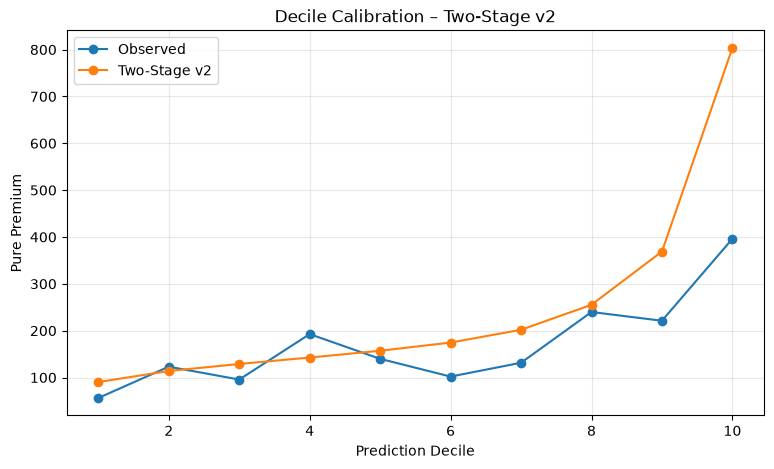

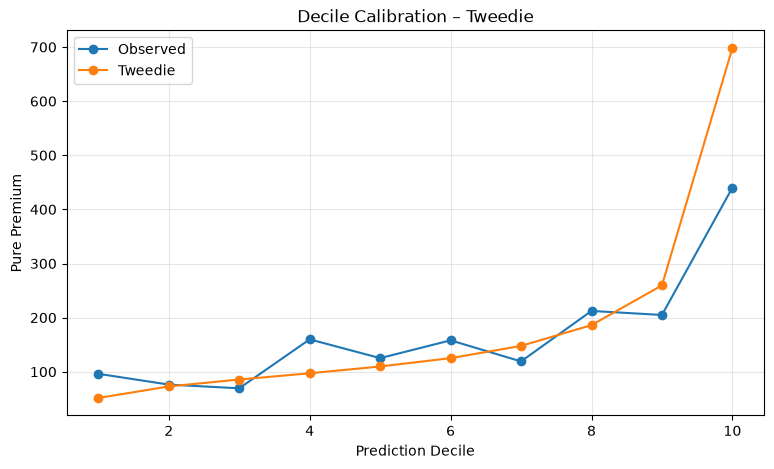

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    two_stage_calibration["decile"],
    two_stage_calibration["actual_pp"],
    marker="o",
    label="Observed",
)

plt.plot(
    two_stage_calibration["decile"],
    two_stage_calibration["predicted_pp"],
    marker="o",
    label="Two-Stage v2",
)

plt.xlabel("Prediction Decile")
plt.ylabel("Pure Premium")
plt.title("Decile Calibration – Two-Stage v2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(9, 5))

plt.plot(
    tweedie_calibration["decile"],
    tweedie_calibration["actual_pp"],
    marker="o",
    label="Observed",
)

plt.plot(
    tweedie_calibration["decile"],
    tweedie_calibration["predicted_pp"],
    marker="o",
    label="Tweedie",
)

plt.xlabel("Prediction Decile")
plt.ylabel("Pure Premium")
plt.title("Decile Calibration – Tweedie")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Ergebnis der Dezilkalibrierung

Die Dezilkalibrierung bestätigt die unterschiedliche Kalibrierungsstruktur der beiden Modelle. Das Two-Stage-Modell zeigt insbesondere im höchsten Prognosedezil eine deutliche Überprognose mit einem Verhältnis von rund 2,03. Beim Tweedie-Modell beträgt dieses Verhältnis rund 1,59.

Auch das Tweedie-Modell weist zwischen einzelnen Dezilen Unter- und Überprognosen auf, insgesamt ist die Abweichung jedoch weniger ausgeprägt. Die Schwankungen der beobachteten Pure Premium zwischen den Dezilen sind zusätzlich durch die stark rechtsschiefe Schadenverteilung beeinflusst.

Die Ergebnisse beziehen sich weiterhin auf den selektionsbeeinflussten beobachtbaren Holdout-Bestand.

Tweedie observable-holdout loss Gini: 0.267730038849298


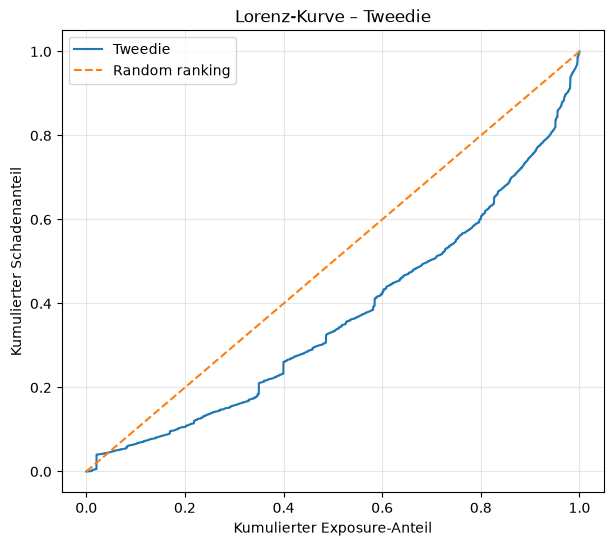

In [50]:
def exposure_weighted_loss_gini(
    actual_loss,
    predicted_pp,
    exposure,
):
    gini_df = pd.DataFrame({
        "actual_loss": np.asarray(actual_loss),
        "predicted_pp": np.asarray(predicted_pp),
        "exposure": np.asarray(exposure),
    })

    gini_df = gini_df.sort_values(
        "predicted_pp",
        ascending=True,
        kind="mergesort",
    )

    cumulative_exposure = np.r_[
        0.0,
        np.cumsum(gini_df["exposure"])
        / gini_df["exposure"].sum(),
    ]

    cumulative_loss = np.r_[
        0.0,
        np.cumsum(gini_df["actual_loss"])
        / gini_df["actual_loss"].sum(),
    ]

    area = np.trapezoid(
        cumulative_loss,
        cumulative_exposure,
    )

    gini = 1 - 2 * area

    return (
        gini,
        cumulative_exposure,
        cumulative_loss,
    )


(
    tweedie_loss_gini,
    tweedie_lorenz_exposure,
    tweedie_lorenz_loss,
) = exposure_weighted_loss_gini(
    actual_loss=test_df["total_claim_amount"],
    predicted_pp=tweedie_pred_test,
    exposure=w_test,
)

print(
    "Tweedie observable-holdout loss Gini:",
    tweedie_loss_gini,
)


plt.figure(figsize=(7, 6))

plt.plot(
    tweedie_lorenz_exposure,
    tweedie_lorenz_loss,
    label="Tweedie",
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking",
)

plt.xlabel("Kumulierter Exposure-Anteil")
plt.ylabel("Kumulierter Schadenanteil")
plt.title("Lorenz-Kurve – Tweedie")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Ergebnis der Rangordnung und finale Modellbewertung

Das Tweedie-Modell erreicht auf dem beobachtbaren Holdout-Bestand einen Loss-Gini von 0,2677 und übertrifft damit den zuvor ermittelten Two-Stage-Wert von rund 0,2358.

Bei der Tweedie-Deviance besitzt das Two-Stage-Modell nur einen sehr kleinen Vorteil (34,3568 gegenüber 34,3645). Gleichzeitig zeigt das direkte Tweedie-Modell eine deutlich bessere Portfolio-Kalibrierung: Die Überprognose des beobachteten Gesamtschadenvolumens beträgt rund 6,40 % gegenüber rund 36,29 % beim Two-Stage-Modell.

In der Gesamtbetrachtung liefert das Tweedie-Modell damit für die direkte Pure-Premium-Prognose die überzeugendere Kombination aus Kalibrierung und Risikorangordnung. Das Two-Stage-Modell bleibt dennoch fachlich wichtig, da es die erwarteten Schäden transparent in Schadenfrequenz und Schadenhöhe zerlegt und dadurch eine deutlich bessere inhaltliche Erklärbarkeit ermöglicht.

Die Bewertung gilt ausschließlich für den selektionsbeeinflussten beobachtbaren Schadenbestand und darf nicht als unverzerrte Aussage für das vollständige Portfolio interpretiert werden.

In [51]:
from joblib import dump

TWEEDIE_HOLDOUT_PATH = (
    PROJECT_ROOT
    / "models"
    / "tweedie_direct_pure_premium_holdout_v1.joblib"
)

TWEEDIE_FULL_PATH = (
    PROJECT_ROOT
    / "models"
    / "tweedie_direct_pure_premium_full_v1.joblib"
)

# 1) Holdout evaluation model:
# trained only on the canonical training partition
dump(
    final_tweedie_pipeline,
    TWEEDIE_HOLDOUT_PATH,
)


# 2) Full-data refit:
# trained on all rows with observable total loss
X_tweedie_full = tweedie_df[
    tweedie_features
].copy()

y_tweedie_full = tweedie_df[
    "tweedie_target"
]

w_tweedie_full = tweedie_df[
    "Exposure"
]

full_tweedie_pipeline = make_tweedie_pipeline(
    power=1.9,
    alpha=0.0,
    max_iter=1500,
)

full_tweedie_pipeline.fit(
    X_tweedie_full,
    y_tweedie_full,
    model__sample_weight=w_tweedie_full,
)

dump(
    full_tweedie_pipeline,
    TWEEDIE_FULL_PATH,
)

print(
    "Holdout artifact:",
    TWEEDIE_HOLDOUT_PATH.relative_to(PROJECT_ROOT),
)

print(
    "Full artifact:",
    TWEEDIE_FULL_PATH.relative_to(PROJECT_ROOT),
)

print(
    "\nFull refit rows:",
    len(X_tweedie_full),
)

print(
    "Full refit exposure:",
    w_tweedie_full.sum(),
)

print(
    "Full model iterations:",
    full_tweedie_pipeline
    .named_steps["model"]
    .n_iter_,
)

print(
    "\nHoldout file exists:",
    TWEEDIE_HOLDOUT_PATH.exists(),
)

print(
    "Full file exists:",
    TWEEDIE_FULL_PATH.exists(),
)

Holdout artifact: models\tweedie_direct_pure_premium_holdout_v1.joblib
Full artifact: models\tweedie_direct_pure_premium_full_v1.joblib

Full refit rows: 668896
Full refit exposure: 353753.82803128974
Full model iterations: 224

Holdout file exists: True
Full file exists: True


In [52]:
X_all_tweedie = model_df[
    tweedie_features
].copy()

tweedie_pred_all = full_tweedie_pipeline.predict(
    X_all_tweedie
)

tweedie_predictions = pd.DataFrame({
    "idpol": model_df["IDpol"].to_numpy(),
    "tweedie_model_version": "tweedie_direct_pp_v1",
    "predicted_pure_premium_tweedie": tweedie_pred_all,
    "exposure_used": model_df["Exposure"].to_numpy(),
})

tweedie_predictions["expected_loss_tweedie"] = (
    tweedie_predictions["predicted_pure_premium_tweedie"]
    * tweedie_predictions["exposure_used"]
)

TWEEDIE_PREDICTIONS_PATH = (
    PROJECT_ROOT
    / "data"
    / "output"
    / "tweedie_predictions.pq"
)

tweedie_predictions.to_parquet(
    TWEEDIE_PREDICTIONS_PATH,
    index=False,
)

print("Shape:", tweedie_predictions.shape)
print(
    "Duplicate IDpol:",
    tweedie_predictions["idpol"].duplicated().sum(),
)
print(
    "Missing predictions:",
    tweedie_predictions[
        "predicted_pure_premium_tweedie"
    ].isna().sum(),
)
print(
    "Prediction min:",
    tweedie_predictions[
        "predicted_pure_premium_tweedie"
    ].min(),
)
print(
    "Prediction max:",
    tweedie_predictions[
        "predicted_pure_premium_tweedie"
    ].max(),
)
print(
    "Expected portfolio loss:",
    tweedie_predictions[
        "expected_loss_tweedie"
    ].sum(),
)
print(
    "File exists:",
    TWEEDIE_PREDICTIONS_PATH.exists(),
)
print(
    "Saved to:",
    TWEEDIE_PREDICTIONS_PATH.relative_to(PROJECT_ROOT),
)

Shape: (678013, 5)
Duplicate IDpol: 0
Missing predictions: 0
Prediction min: 5.591653754214951
Prediction max: 18661.099356718336
Expected portfolio loss: 59631359.417399034
File exists: True
Saved to: data\output\tweedie_predictions.pq


## Fazit – Tweedie Challenger

Für die direkte Modellierung der Pure Premium wurde ein Tweedie-Regressionsmodell mit Log-Link entwickelt. Die Modellspezifikation wurde ausschließlich auf den Trainingsdaten festgelegt. Als finale Konfiguration wurden `power = 1,9` und `alpha = 0` gewählt.

In der wiederholten Cross-Validation verbessert das Modell die Tweedie-Deviance gegenüber der konstanten Baseline um rund 2,71 %. Auf dem beobachtbaren Holdout-Bestand erreicht das finale Modell eine Mean Tweedie Deviance von 34,3645 und überschätzt das beobachtete Gesamtschadenvolumen um rund 6,40 %.

Im direkten Vergleich besitzt das Two-Stage-Modell bei der Tweedie-Deviance nur einen sehr kleinen Vorteil, während das Tweedie-Modell eine deutlich bessere Kalibrierung des Gesamtschadenvolumens und mit einem Loss-Gini von 0,2677 eine stärkere Risikorangordnung zeigt.

Damit stellt Tweedie einen leistungsfähigen direkten Pure-Premium-Challenger dar. Das Two-Stage-Modell bleibt parallel relevant, da die getrennte Modellierung von Schadenfrequenz und Schadenhöhe eine bessere fachliche Interpretierbarkeit ermöglicht.

Die Holdout-Vergleiche beziehen sich auf den beobachtbaren Schadenbestand. Aufgrund fehlender Schadenhöhen bei einem Teil der Schadenpolicen ist diese Population selektionsbeeinflusst; entsprechende Kalibrierungswerte dürfen daher nicht als unverzerrte Aussage über das vollständige Portfolio interpretiert werden.

Nach Abschluss der Modellbewertung wurde das finale Tweedie-Modell auf allen 668.896 Policen mit beobachtbarem Gesamtschaden neu geschätzt. Anschließend wurden Pure-Premium-Prognosen für alle 678.013 Policen des Portfolios erzeugt und als separates Prediction-Artefakt gespeichert.